In [18]:
# Supervised Classification - KNN
# import2
# libraries
import pandas as pd
import numpy as np
import statsmodels.api as sm
from statsmodels.stats.outliers_influence import variance_inflation_factor
from sklearn.model_selection import train_test_split
from sklearn.metrics import accuracy_score
from sklearn.metrics import confusion_matrix
import seaborn as sns
from sklearn.neighbors import KNeighborsClassifier
from sklearn.tree import plot_tree, DecisionTreeClassifier

In [3]:
wine = pd.read_csv('white_wine.csv')
wine

,fixed acidity,volatile acidity,citric acid,residual sugar,chlorides,free sulfur dioxide,total sulfur dioxide,density,pH,sulphates,alcohol,quality
0,7.0,0.27,0.36,20.7,0.045,45.0,170.0,1.0010,3.00,0.45,8.8,6.0
1,6.3,0.30,0.34,1.6,0.049,14.0,132.0,0.9940,3.30,0.49,9.5,6.0
2,8.1,0.28,0.40,6.9,0.050,30.0,97.0,0.9951,3.26,0.44,10.1,6.0
3,7.2,0.23,0.32,8.5,0.058,47.0,186.0,0.9956,3.19,0.40,9.9,6.0
4,7.2,0.23,0.32,8.5,0.058,47.0,186.0,0.9956,3.19,0.40,9.9,6.0
...,...,...,...,...,...,...,...,...,...,...,...,...
515,6.1,0.31,0.26,2.2,0.051,28.0,167.0,0.9926,3.37,0.47,10.4,6.0
516,6.8,0.18,0.37,1.6,0.055,47.0,154.0,0.9934,3.08,0.45,9.1,5.0
517,7.4,0.15,0.42,1.7,0.045,49.0,154.0,0.9920,3.00,0.60,10.4,6.0
518,5.9,0.13,0.28,1.9,0.050,20.0,78.0,0.9918,3.43,0.64,10.8,6.0


In [4]:
wine.info()

<class 'pandas.core.frame.DataFrame'>
RangeIndex: 520 entries, 0 to 519
Data columns (total 12 columns):
 #   Column                Non-Null Count  Dtype  
---  ------                --------------  -----  
 0   fixed acidity         520 non-null    float64
 1   volatile acidity      520 non-null    float64
 2   citric acid           520 non-null    float64
 3   residual sugar        520 non-null    float64
 4   chlorides             520 non-null    float64
 5   free sulfur dioxide   520 non-null    float64
 6   total sulfur dioxide  520 non-null    float64
 7   density               520 non-null    float64
 8   pH                    519 non-null    float64
 9   sulphates             519 non-null    float64
 10  alcohol               519 non-null    float64
 11  quality               519 non-null    float64
dtypes: float64(12)
memory usage: 48.9 KB


In [5]:
# describe
wine.describe().loc[['mean','min','max']].T

,mean,min,max
fixed acidity,6.812115,5.0000,10.2000
volatile acidity,0.289260,0.1000,0.9050
citric acid,0.338327,0.0000,0.8800
residual sugar,6.624615,0.8000,22.0000
chlorides,0.047781,0.0200,0.3460
free sulfur dioxide,37.146154,3.0000,131.0000
total sulfur dioxide,146.545192,41.0000,313.0000
density,0.995374,0.9899,1.0033
pH,3.210289,2.8700,3.7200
sulphates,0.486936,0.2700,0.8500


In [7]:
# set the quality as the target, if quality > 6, change it to 1, else 0
wine['label'] = np.where(wine['quality']>6,1,0)
wine

,fixed acidity,volatile acidity,citric acid,residual sugar,chlorides,free sulfur dioxide,total sulfur dioxide,density,pH,sulphates,alcohol,quality,label
0,7.0,0.27,0.36,20.7,0.045,45.0,170.0,1.0010,3.00,0.45,8.8,6.0,0
1,6.3,0.30,0.34,1.6,0.049,14.0,132.0,0.9940,3.30,0.49,9.5,6.0,0
2,8.1,0.28,0.40,6.9,0.050,30.0,97.0,0.9951,3.26,0.44,10.1,6.0,0
3,7.2,0.23,0.32,8.5,0.058,47.0,186.0,0.9956,3.19,0.40,9.9,6.0,0
4,7.2,0.23,0.32,8.5,0.058,47.0,186.0,0.9956,3.19,0.40,9.9,6.0,0
...,...,...,...,...,...,...,...,...,...,...,...,...,...
515,6.1,0.31,0.26,2.2,0.051,28.0,167.0,0.9926,3.37,0.47,10.4,6.0,0
516,6.8,0.18,0.37,1.6,0.055,47.0,154.0,0.9934,3.08,0.45,9.1,5.0,0
517,7.4,0.15,0.42,1.7,0.045,49.0,154.0,0.9920,3.00,0.60,10.4,6.0,0
518,5.9,0.13,0.28,1.9,0.050,20.0,78.0,0.9918,3.43,0.64,10.8,6.0,0


In [10]:
# check the value
wine['label'].value_counts()

label
0    422
1     98
Name: count, dtype: int64

<Axes: xlabel='density', ylabel='alcohol'>

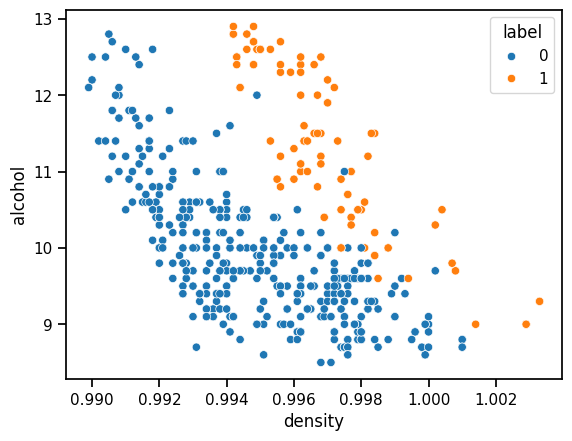

In [11]:
# let's take a look for the scatter visualization
sns.set_context('notebook',font_scale=1)
sns.scatterplot(data=wine,x='density',y='alcohol',hue='label')

In [13]:
# last time, we see null value. fill the null value
wine[['density','alcohol']].isnull().sum()

density    0
alcohol    1
dtype: int64

In [14]:
# quick handle, it's only 1 data point, fill it with median
wine['alcohol'].fillna(wine['alcohol'].median(),inplace=True)
# and check again
wine[['density','alcohol']].isnull().sum()

/var/folders/zv/zjqsfp4j6dggngswjnpbdkt00000gn/T/ipykernel_11358/1473392472.py:2: FutureWarning: A value is trying to be set on a copy of a DataFrame or Series through chained assignment using an inplace method.
The behavior will change in pandas 3.0. This inplace method will never work because the intermediate object on which we are setting values always behaves as a copy.

For example, when doing 'df[col].method(value, inplace=True)', try using 'df.method({col: value}, inplace=True)' or df[col] = df[col].method(value) instead, to perform the operation inplace on the original object.


  wine['alcohol'].fillna(wine['alcohol'].median(),inplace=True)


density    0
alcohol    0
dtype: int64

In [15]:
# define feature and target
x = wine[['density','alcohol']]
y = wine[['label']]
display(x,y)

,density,alcohol
0,1.0010,8.8
1,0.9940,9.5
2,0.9951,10.1
3,0.9956,9.9
4,0.9956,9.9
...,...,...
515,0.9926,10.4
516,0.9934,9.1
517,0.9920,10.4
518,0.9918,10.8


,label
0,0
1,0
2,0
3,0
4,0
...,...
515,0
516,0
517,0
518,0


In [61]:
wine[['density','alcohol','label']].value_counts().reset_index()
# wine['alcohol'].value_counts().reset_index()

,density,alcohol,label,count
0,0.9975,8.7,0,6
1,0.9979,9.0,0,5
2,0.9954,9.8,0,5
3,0.9954,10.4,0,5
4,0.9962,8.9,0,4
...,...,...,...,...
364,0.9940,10.7,0,1
365,0.9940,10.6,0,1
366,0.9940,10.4,0,1
367,0.9940,9.9,0,1


In [45]:
# feature selection
x_train, x_test, y_train, y_test = train_test_split(
x,
y,
stratify=y,
random_state=2020,
test_size=0.2
)

In [46]:
# let's define the model
knn = KNeighborsClassifier(n_neighbors=3)
knn.fit(x_train,y_train)
y_predict_class = knn.predict(x_test)

/Users/dikjaya/miniconda3/lib/python3.12/site-packages/sklearn/neighbors/_classification.py:238: DataConversionWarning: A column-vector y was passed when a 1d array was expected. Please change the shape of y to (n_samples,), for example using ravel().
  return self._fit(X, y)


In [47]:
print('the model accuracy on data test is: ',accuracy_score(y_test,y_predict_class))

the model accuracy on data test is:  0.9038461538461539


In [48]:
# implementing the min_max scaler
from sklearn.preprocessing import MinMaxScaler

In [49]:
scale = MinMaxScaler()
scale.fit(x_train) # preprocess for scaling
x_train_scaled = scale.transform(x_train)
x_test_scaled = scale.transform(x_test)
display(x_train_scaled)

array([[0.34586466, 0.45454545],
       [0.36842105, 0.11363636],
       [0.96992481, 0.11363636],
       [0.46616541, 0.13636364],
       [0.34586466, 0.43181818],
       [0.63909774, 0.15909091],
       [0.12781955, 0.56818182],
       [0.45112782, 0.34090909],
       [0.46616541, 0.09090909],
       [0.15037594, 0.52272727],
       [0.54135338, 0.09090909],
       [0.61654135, 0.29545455],
       [0.15037594, 0.43181818],
       [0.54135338, 0.20454545],
       [0.59398496, 0.45454545],
       [0.54135338, 0.09090909],
       [0.13533835, 0.45454545],
       [0.30075188, 0.45454545],
       [0.4887218 , 0.22727273],
       [0.28571429, 0.45454545],
       [0.03759398, 0.97727273],
       [0.36090226, 0.88636364],
       [0.42105263, 0.61363636],
       [0.63157895, 0.18181818],
       [0.63157895, 0.06818182],
       [0.54135338, 0.18181818],
       [0.05263158, 0.79545455],
       [0.58646617, 0.18181818],
       [0.53383459, 0.13636364],
       [0.36842105, 0.31818182],
       [0.

In [50]:
# let's do the model fitting
knn = KNeighborsClassifier(n_neighbors=3)
knn = knn.fit(x_train_scaled,y_train)
y_predict_class = knn.predict(x_test_scaled)

/Users/dikjaya/miniconda3/lib/python3.12/site-packages/sklearn/neighbors/_classification.py:238: DataConversionWarning: A column-vector y was passed when a 1d array was expected. Please change the shape of y to (n_samples,), for example using ravel().
  return self._fit(X, y)


In [51]:
print('the model accuracy on data test after scaled is: ',accuracy_score(y_test,y_predict_class))

the model accuracy on data test after scaled is:  0.9807692307692307


In [52]:
# create iterations for comparing the training accuracy and test accuracy
k = np.arange(1,30,2)
training_accuracies = []
test_accuracies = []
score = 0

for i in k:
    knn = KNeighborsClassifier(n_neighbors=i)
    knn.fit(x_train_scaled,y_train)

    y_predict_train = knn.predict(x_train_scaled)
    training_accuracies.append(accuracy_score(y_train,y_predict_train))

    y_predict_test = knn.predict(x_test_scaled)
    acc_score = accuracy_score(y_test,y_predict_test)
    test_accuracies.append(acc_score)

    if score < acc_score:
        score = acc_score
        best_k = i

/Users/dikjaya/miniconda3/lib/python3.12/site-packages/sklearn/neighbors/_classification.py:238: DataConversionWarning: A column-vector y was passed when a 1d array was expected. Please change the shape of y to (n_samples,), for example using ravel().
  return self._fit(X, y)
/Users/dikjaya/miniconda3/lib/python3.12/site-packages/sklearn/neighbors/_classification.py:238: DataConversionWarning: A column-vector y was passed when a 1d array was expected. Please change the shape of y to (n_samples,), for example using ravel().
  return self._fit(X, y)
/Users/dikjaya/miniconda3/lib/python3.12/site-packages/sklearn/neighbors/_classification.py:238: DataConversionWarning: A column-vector y was passed when a 1d array was expected. Please change the shape of y to (n_samples,), for example using ravel().
  return self._fit(X, y)
/Users/dikjaya/miniconda3/lib/python3.12/site-packages/sklearn/neighbors/_classification.py:238: DataConversionWarning: A column-vector y was passed when a 1d array was 

In [53]:
df_k = pd.DataFrame(k,columns=['k'])
df_k['training_accuracy'] = pd.DataFrame(training_accuracies,columns=['temp'])
df_k['test_accuracy'] = pd.DataFrame(test_accuracies,columns=['temp'])
df_k

,k,training_accuracy,test_accuracy
0,1,0.997596,0.971154
1,3,0.983173,0.980769
2,5,0.975962,0.980769
3,7,0.971154,0.971154
4,9,0.980769,0.980769
5,11,0.978365,0.980769
6,13,0.978365,0.971154
7,15,0.973558,0.971154
8,17,0.963942,0.990385
9,19,0.956731,0.980769


In [54]:
# pd.melt
df_melted = pd.melt(df_k,id_vars=['k'],value_vars=['training_accuracy','test_accuracy'],var_name='attribute',value_name='value')
df_melted

,k,attribute,value
0,1,training_accuracy,0.997596
1,3,training_accuracy,0.983173
2,5,training_accuracy,0.975962
3,7,training_accuracy,0.971154
4,9,training_accuracy,0.980769
5,11,training_accuracy,0.978365
6,13,training_accuracy,0.978365
7,15,training_accuracy,0.973558
8,17,training_accuracy,0.963942
9,19,training_accuracy,0.956731


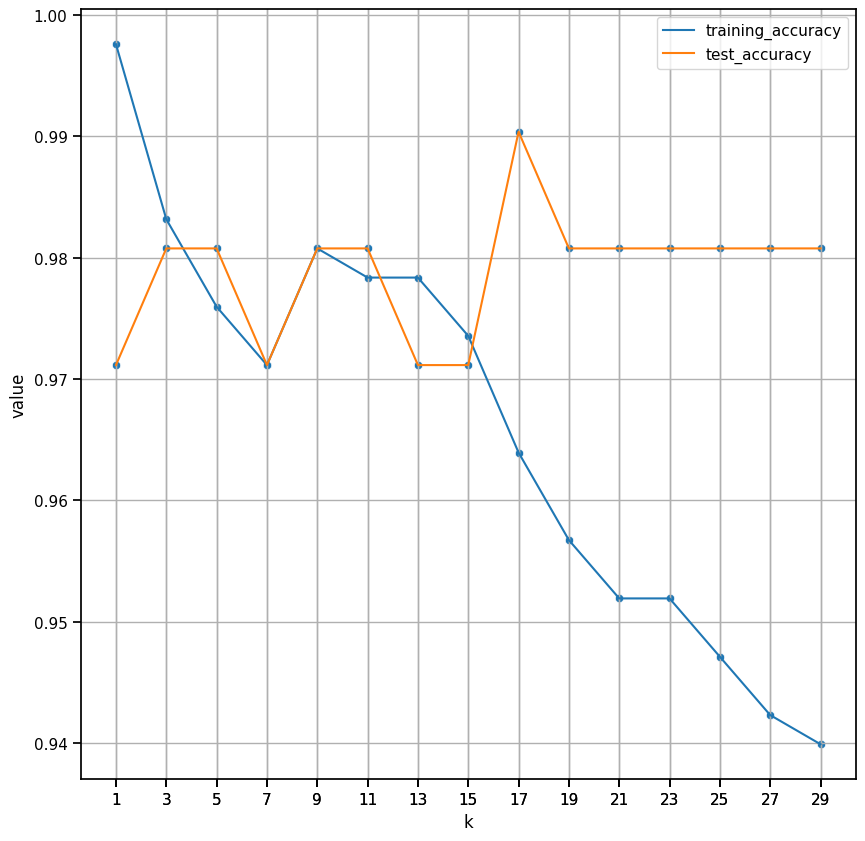

In [55]:
# plot the 2 lines
import matplotlib.pyplot as plt
plt.figure(figsize=(10,10))
sns.set_context('notebook',font_scale=1)
ax = sns.lineplot(data=df_melted,x='k',y='value',hue='attribute')
sns.scatterplot(data=df_melted,x='k',y='value')
ax.set_xticks(df_melted['k'])
plt.grid()

In [56]:
print('best k:',best_k)
print('best accuracy:',score)

best k: 17
best accuracy: 0.9903846153846154


/Users/dikjaya/miniconda3/lib/python3.12/site-packages/sklearn/neighbors/_classification.py:238: DataConversionWarning: A column-vector y was passed when a 1d array was expected. Please change the shape of y to (n_samples,), for example using ravel().
  return self._fit(X, y)


KNeighborsClassifier(n_neighbors=29)